# Customer Churn Analysis

## Business Problem
A telecom company is losing customers. The goal of this project is to find
out why customers leave (churn) and which customers are most at risk.
# Questions I want to answer
1. What is the overall churn rate?
2. Which contract types have the highest churn?
3. Does tenure affect churn?
4. Do higher monthly charges lead to more churn?
5. Which services (tech support, online security, etc.) help keep customers?
## Tools
Python, Pandas, Matplotlib, Seaborn, Power BI

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [7]:
df["TotalCharges"].dtype

dtype('float64')

In [8]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

### Handling missing TotalCharges
11 customers have a blank TotalCharges. All of them have tenure = 0, meaning
they just joined and have not been billed yet. They are only ~0.16% of the
data, so I am dropping these rows.

In [9]:
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
df.shape

(7032, 21)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["customerID"].duplicated().sum()

np.int64(0)

In [12]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

SeniorCitizen
No     5890
Yes    1142
Name: count, dtype: int64

In [13]:
df["ChurnFlag"] = df["Churn"].map({"Yes": 1, "No": 0})

In [14]:
df["ChurnFlag"].value_counts()

ChurnFlag
0    5163
1    1869
Name: count, dtype: int64

In [15]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72],
                           labels=["0-1 yr", "1-2 yr", "2-4 yr", "4-6 yr"])

In [16]:
df["TenureGroup"].value_counts().sort_index()

TenureGroup
0-1 yr    2175
1-2 yr    1024
2-4 yr    1594
4-6 yr    2239
Name: count, dtype: int64

In [17]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'ChurnFlag',
       'TenureGroup'],
      dtype='str')

In [18]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
ChurnFlag           0
TenureGroup         0
dtype: int64

In [19]:
df.to_csv("../data/churn_clean.csv", index=False)

## Data Cleaning Summary
- Converted TotalCharges from text to numeric; found 11 hidden blanks
- Dropped 11 rows (tenure = 0, new customers not yet billed)
- No duplicate rows or duplicate customer IDs
- Converted SeniorCitizen from 0/1 to No/Yes
- Created ChurnFlag (1 = churned, 0 = stayed) and TenureGroup columns
- Final dataset: 7,032 rows

## Exploratory Data Analysis

In [20]:
churn_rate = df["ChurnFlag"].mean() * 100
print(f"Overall churn rate: {churn_rate:.2f}%")

Overall churn rate: 26.58%


In [21]:
df.groupby("Contract")["ChurnFlag"].mean().mul(100).round(2).sort_values(ascending=False)

Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: ChurnFlag, dtype: float64

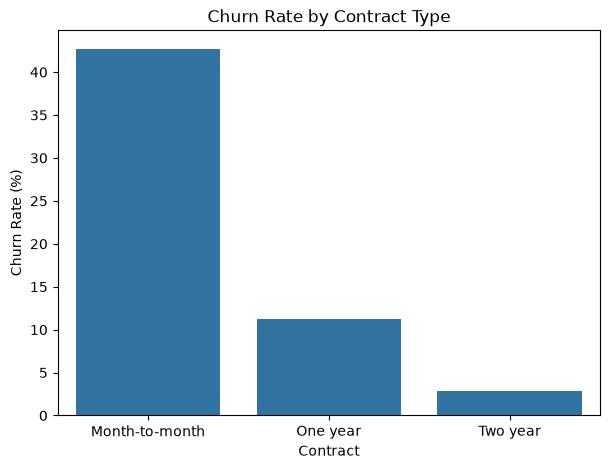

In [22]:
contract_churn = df.groupby("Contract")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(7, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values)
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract")
plt.savefig("../outputs/churn_by_contract.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Month-to-month customers churn at 42.7%, far above the overall
rate of 26.6%, while two-year customers churn at only 2.9%. Customers without
a long-term commitment are the main churn risk.

**Recommendation:** Offer discounts or perks to move month-to-month customers
onto 1- or 2-year contracts.

In [23]:
df.groupby("InternetService")["ChurnFlag"].mean().mul(100).round(2).sort_values(ascending=False)

InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: ChurnFlag, dtype: float64

In [24]:
df.groupby("InternetService")["MonthlyCharges"].mean().round(2)

InternetService
DSL            58.09
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64

In [25]:
pd.crosstab(df["InternetService"], df["Contract"], normalize="index").mul(100).round(1)

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,50.6,23.6,25.8
Fiber optic,68.7,17.4,13.9
No,34.5,23.9,41.6


In [26]:
fiber = df[df["InternetService"] == "Fiber optic"]
fiber.groupby("TechSupport")["ChurnFlag"].mean().mul(100).round(2)

TechSupport
No     49.37
Yes    22.63
Name: ChurnFlag, dtype: float64

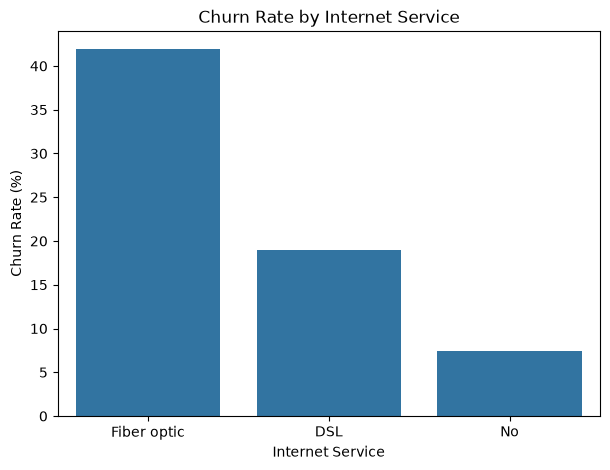

In [27]:
internet_churn = df.groupby("InternetService")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(7, 5))
sns.barplot(x=internet_churn.index, y=internet_churn.values)
plt.title("Churn Rate by Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Internet Service")
plt.savefig("../outputs/churn_by_internet.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Fiber optic customers churn at 41.9%, far above DSL (19.0%).
68.7% of fiber customers are on month-to-month contracts, and fiber customers
without tech support churn at 49.4% compared with 22.6% for those with it.

**Recommendation:** Rather than moving fiber customers to a cheaper service,
offer fiber customers free or discounted tech support trials and incentives
to move to 1-2 year contracts.

In [28]:
df.groupby("InternetService")["MonthlyCharges"].mean().round(2)

InternetService
DSL            58.09
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64

In [29]:
cols = ["OnlineSecurity", "PaymentMethod", "PaperlessBilling",
        "SeniorCitizen", "Partner", "Dependents", "gender"]

for col in cols:
    print(col)
    print(df.groupby(col)["ChurnFlag"].mean().mul(100).round(2).sort_values(ascending=False))
    print("-" * 30)

OnlineSecurity
OnlineSecurity
No                     41.78
Yes                    14.64
No internet service     7.43
Name: ChurnFlag, dtype: float64
------------------------------
PaymentMethod
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: ChurnFlag, dtype: float64
------------------------------
PaperlessBilling
PaperlessBilling
Yes    33.59
No     16.38
Name: ChurnFlag, dtype: float64
------------------------------
SeniorCitizen
SeniorCitizen
Yes    41.68
No     23.65
Name: ChurnFlag, dtype: float64
------------------------------
Partner
Partner
No     32.98
Yes    19.72
Name: ChurnFlag, dtype: float64
------------------------------
Dependents
Dependents
No     31.28
Yes    15.53
Name: ChurnFlag, dtype: float64
------------------------------
gender
gender
Female    26.96
Male      26.20
Name: ChurnFlag, dtype: float64
------------------------------


**Insight:** Customers paying by electronic check churn at 45.3%, compared
with 15-17% for automatic payment methods.
**Recommendation:** Encourage customers to switch to automatic payments
with small incentives such as a bill credit.

**Insight:** Customers without online security or tech support churn at
about 42-49%, versus 15-23% for those who have them.
**Recommendation:** Bundle or discount security and support services,
especially for new fiber customers.

**Insight:** Gender shows no meaningful difference in churn (27.0% vs 26.2%).
Retention efforts should not be targeted by gender.

In [30]:
for col in ["Partner", "Dependents"]:
    print(col)
    print(df.groupby(col)["ChurnFlag"].mean().mul(100).round(2))
    print("-" * 30)

Partner
Partner
No     32.98
Yes    19.72
Name: ChurnFlag, dtype: float64
------------------------------
Dependents
Dependents
No     31.28
Yes    15.53
Name: ChurnFlag, dtype: float64
------------------------------


**Insight:** Customers without a partner churn at 33.0% (vs 19.7% with one),
and customers without dependents churn at 31.3% (vs 15.5% with them).
**Recommendation:** Treat single customers without dependents as a higher-risk
segment for proactive retention offers, and consider family-oriented plans.

In [31]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.65,61.31,2555.34
Yes,17.98,74.44,1531.80


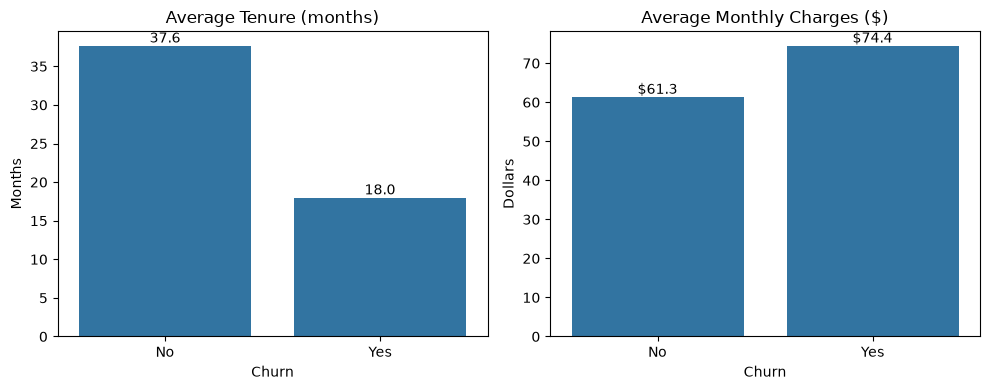

In [32]:
avg = df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Plot 1: average tenure
ax1 = sns.barplot(x=avg.index, y=avg["tenure"], ax=axes[0])
ax1.bar_label(ax1.containers[0], fmt="%.1f")
axes[0].set_title("Average Tenure (months)")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Months")

# Plot 2: average monthly charges
ax2 = sns.barplot(x=avg.index, y=avg["MonthlyCharges"], ax=axes[1])
ax2.bar_label(ax2.containers[0], fmt="$%.1f")
axes[1].set_title("Average Monthly Charges ($)")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Dollars")

plt.tight_layout()
plt.savefig("../outputs/avg_tenure_charges.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Churned customers stay about half as long as retained customers
(18.0 vs 37.7 months on average) and pay about $13 more per month
($74.44 vs $61.31).

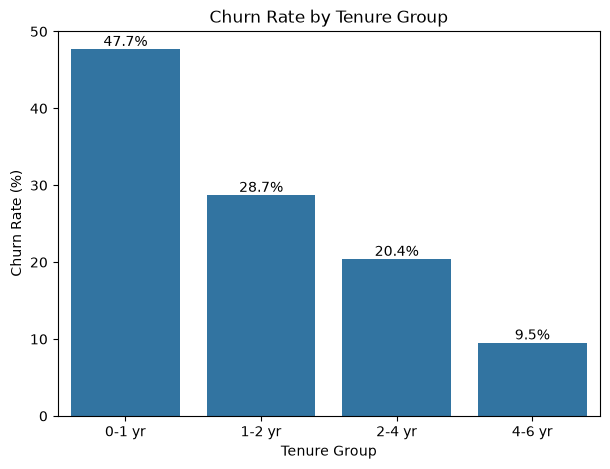

In [33]:
tenure_churn = df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean().mul(100)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=tenure_churn.index, y=tenure_churn.values)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Tenure Group")
plt.savefig("../outputs/churn_by_tenure_group.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Churn is concentrated early in the customer lifecycle. Customers
in their first year churn at 47.7%, falling to 9.5% after four years. Churned
customers had an average tenure of about 18 months, half the 38 months of
retained customers.

**Recommendation:** Invest in the first 12 months: onboarding, early check-ins,
and offers that move new month-to-month customers onto longer contracts.

TenureGroup
0-1 yr    55.5
1-2 yr    15.7
2-4 yr    17.4
4-6 yr    11.4
Name: proportion, dtype: float64


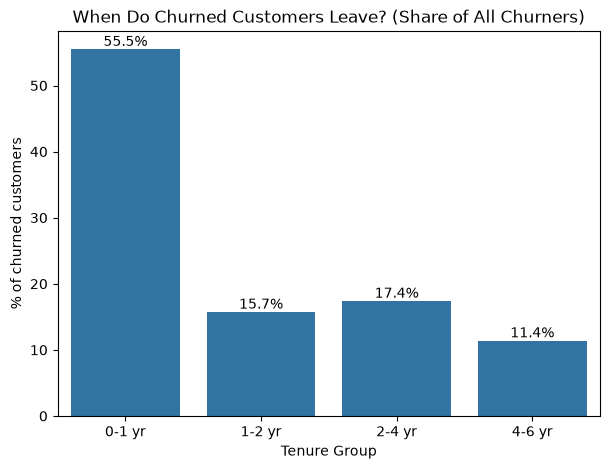

In [34]:
churned = df[df["Churn"] == "Yes"]

share = churned["TenureGroup"].value_counts(normalize=True).mul(100).sort_index()
print(share.round(1))

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=share.index, y=share.values)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("When Do Churned Customers Leave? (Share of All Churners)")
plt.ylabel("% of churned customers")
plt.xlabel("Tenure Group")
plt.savefig("../outputs/churners_by_tenure_group.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Churn is concentrated early in the customer lifecycle. 55.5% of all
churned customers left within their first year, and first-year customers churn
at 47.7%, falling to 9.5% for customers with 4+ years of tenure.

**Recommendation:** Prioritize the first 12 months with onboarding support,
early check-ins, and offers that move new month-to-month customers onto
1-2 year contracts.

In [35]:
df.to_csv("../data/churn_clean.csv", index=False)

# Conclusion: Customer Churn Analysis

## Summary
Of 7,032 customers, **1,869 churned (26.58%)**. The analysis shows that churn is
concentrated among new customers on flexible contracts who lack support services
and pay by electronic check.

## Key Findings

| Driver | Highest-risk group | Churn rate | Lowest-risk group | Churn rate |
|---|---|---|---|---|
| Contract | Month-to-month | 42.71% | Two year | 2.85% |
| Payment method | Electronic check | 45.29% | Credit card (automatic) | 15.25% |
| Internet service | Fiber optic | 41.89% | No internet | 7.43% |
| Online security | No | 41.78% | Yes | 14.64% |
| Tenure group | 0-1 yr | 47.7% | 4-6 yr | 9.5% |
| Senior citizen | Yes | 41.68% | No | 23.65% |
| Partner | No | 32.98% | Yes | 19.72% |
| Dependents | No | 31.28% | Yes | 15.53% |

- **Churn happens early:** 55.5% of all churned customers left within their first year.
  Churned customers had an average tenure of 17.98 months, versus 37.65 months for
  retained customers.
- **Higher bills are associated with churn:** churned customers paid an average of
  $74.44 per month, versus $61.31 for retained customers.
- **Fiber optic customers:** 68.7% are on month-to-month contracts. Fiber customers
  without tech support churn at 49.37%, versus 22.63% with it.
- **Gender has no meaningful effect** on churn (26.96% vs 26.20%).

## Recommendations
1. **Move customers to longer contracts:** offer discounts or perks to month-to-month
   customers who switch to 1- or 2-year plans.
2. **Focus on the first 12 months:** improve onboarding and run early check-ins with
   new customers.
3. **Promote automatic payments:** offer a small bill credit to customers paying by
   electronic check.
4. **Bundle support services:** offer free or discounted tech support and online
   security trials, especially to fiber customers.
5. **Target high-risk segments:** prioritize retention offers for new, single customers
   without dependents.
